<a href="https://colab.research.google.com/github/Krishna9423-wagh/numpy-colab-projects/blob/main/linear_regression_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

House price prediction using the normal equation and gradient descent, NumPy only.

Generate seeded housing data with a known formula

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 500
area     = np.random.uniform(500, 3500, n)
bedrooms = np.random.randint(1, 6, n)
age      = np.random.uniform(0, 40, n)


noise = np.random.normal(0, 15000, n)
price = 50000 + 120*area + 8000*bedrooms - 600*age + noise

X = np.column_stack([np.ones(n), area, bedrooms, age])
y = price.reshape(-1, 1)


idx = np.random.permutation(n)
split = int(0.8 * n)
train_idx, test_idx = idx[:split], idx[split:]
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print(X_train.shape, X_test.shape)

(400, 4) (100, 4)


Check the determinant, then solve with inverse and transpose

In [2]:
XtX = X_train.T @ X_train
det = np.linalg.det(XtX)
print("Determinant:", det)

if abs(det) > 1e-8:
    theta_normal = np.linalg.inv(XtX) @ X_train.T @ y_train
    print("Normal equation theta:\n", theta_normal.ravel())
else:
    print("Matrix is singular, cannot invert")

Determinant: 5.503787532399881e+18
Normal equation theta:
 [50269.92839658   120.49252626  7009.33549752  -535.43535713]


Gradient descent using the @ operator

In [3]:

mean = X_train[:, 1:].mean(axis=0)
std  = X_train[:, 1:].std(axis=0)

Xs_train = X_train.copy(); Xs_train[:, 1:] = (X_train[:, 1:] - mean) / std
Xs_test  = X_test.copy();  Xs_test[:, 1:]  = (X_test[:, 1:]  - mean) / std

theta = np.zeros((4, 1))
lr, epochs = 0.1, 1000
m = len(y_train)
losses = []

for _ in range(epochs):
    error    = Xs_train @ theta - y_train
    gradient = (2 / m) * Xs_train.T @ error
    theta   -= lr * gradient
    losses.append((error**2).mean())

print("Final theta (scaled space):", theta.ravel())

Final theta (scaled space): [300171.61971862 106476.94604926  10037.5391367   -6238.30548306]


RMSE, R² and a predicted-vs-actual plot

Normal equation -> RMSE: 14,852, R²: 0.9822
Gradient descent -> RMSE: 14,852, R²: 0.9822


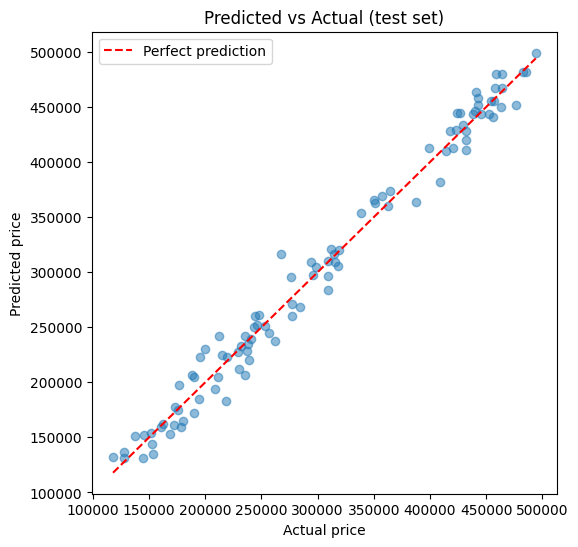

In [4]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1 - ss_res / ss_tot

pred_normal = X_test @ theta_normal
pred_gd     = Xs_test @ theta

print(f"Normal equation -> RMSE: {rmse(y_test, pred_normal):,.0f}, R²: {r2(y_test, pred_normal):.4f}")
print(f"Gradient descent -> RMSE: {rmse(y_test, pred_gd):,.0f}, R²: {r2(y_test, pred_gd):.4f}")

plt.figure(figsize=(6,6))
plt.scatter(y_test, pred_normal, alpha=0.5)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual price"); plt.ylabel("Predicted price")
plt.title("Predicted vs Actual (test set)"); plt.legend()
plt.show()